# SARIMA / AutoSARIMA

L'anàlisi exploratòria (EDA) va confirmar dos trets centrals de les nostres sèries: **tendència creixent** i **estacionalitat anual forta** (pics a tardor, vall a agost). El test ADF també va mostrar que la sèrie no és estacionària en nivell però sí en primera diferència. Tot plegat fa que la família de models **SARIMA** sigui una elecció natural i ben fonamentada per a aquest problema.

Un model SARIMA(p,d,q)(P,D,Q)₁₂ gestiona explícitament:
- La **no-estacionarietat** via diferenciació (d=1 confirmat per l'ADF, D=1 per eliminar l'estacionalitat)
- L'**autocorrelació** a curt termini via els termes AR/MA (p, q)
- L'**estacionalitat** periòdica de 12 mesos via els termes estacionals (P, Q)

En lloc d'escollir manualment els ordres — un procés costós i subjectiu per a 7 sèries independents — fem servir **`auto_arima` de pmdarima**, que cerca l'ordre òptim minimitzant l'AIC. Obtenim així un model ben calibrat per a cada tecnologia sense intervenció manual, i podem veure quins ordres tria el criteri per a cada sèrie (un resultat interessant per si sol).

S'ha provat també una variant **SARIMAX** amb dummies de COVID i MOVES III com a variables exògenes. Durant el període de test (2025), però, el COVID és zero i MOVES III és actiu tots els mesos, de manera que les prediccions resulten pràcticament idèntiques. Reportem només **AutoSARIMA** per evitar la redundància.

> **Prerequisit:** executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from evaluation import compute_metrics
from models import SARIMAForecaster
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
train_set   = pd.read_csv(DATA_DIR / 'train_set.csv',   parse_dates=['date'])
test_set    = pd.read_csv(DATA_DIR / 'test_set.csv',    parse_dates=['date'])

# Dummies exògenes: una fila per mes (independentment de tecnologia)
exog_train = train_set[train_set['Tecnologia'] == 'Total'][['date', 'covid_dummy', 'moves3_dummy']].set_index('date')
exog_test  = test_set[test_set['Tecnologia'] == 'Total'][['date', 'covid_dummy', 'moves3_dummy']].set_index('date')
print(f'Train: {len(pivot_train)} mesos | Exog train shape: {exog_train.shape}')
print(f'Test:  {len(pivot_test)} mesos | Exog test shape:  {exog_test.shape}')

Train: 96 mesos | Exog train shape: (96, 2)
Test:  12 mesos | Exog test shape:  (12, 2)


## 1. AutoSARIMA — selecció d'ordres i predicció


In [3]:
H = len(pivot_test)

sarima_forecasts = {}
sarima_orders    = {}
forecast_records = []
metrics_records  = []

print('Ajustant AutoSARIMA per tecnologia...')
for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna()
    y_test  = pivot_test[tech].values

    model = SARIMAForecaster(name='AutoSARIMA')
    model.fit(y_train)
    y_pred = np.maximum(model.predict(H), 0)
    sarima_forecasts[tech] = y_pred

    order = model._model.order
    seas  = model._model.seasonal_order
    sarima_orders[tech] = {'order': order, 'seasonal_order': seas}
    print(f'  {tech:35s}: SARIMA{order}×{seas}')

    m = compute_metrics(y_test, y_pred, y_train.values)
    m.update({'Tecnologia': tech, 'Model': 'AutoSARIMA'})
    metrics_records.append(m)

    for i, date in enumerate(pivot_test.index):
        forecast_records.append({'date': date, 'Tecnologia': tech,
                                 'Model': 'AutoSARIMA',
                                 'predicted': y_pred[i], 'actual': y_test[i]})

Ajustant AutoSARIMA per tecnologia...
  Elèctric                           : SARIMA(3, 1, 1)×(2, 1, 0, 12)
  Gasolina Mild Hybrid               : SARIMA(1, 1, 3)×(0, 1, 1, 12)
  Gasolina/Elèctric                  : SARIMA(0, 1, 1)×(0, 1, 1, 12)
  Gasolina/Elèctric Endollable       : SARIMA(2, 1, 1)×(0, 1, 1, 12)
  Diesel Mild Hybrid                 : SARIMA(0, 1, 2)×(2, 1, 0, 12)
  Diesel/Elèctric Endollable         : SARIMA(0, 1, 1)×(2, 1, 0, 12)
  Total                              : SARIMA(0, 1, 1)×(0, 1, 1, 12)


## 2. Diagnòstic de residus (sèrie Total)

In [4]:
from statsmodels.stats.diagnostic import acorr_ljungbox

y_total = pivot_train['Total'].dropna()
model_diag = SARIMAForecaster(name='SARIMA_diag')
model_diag.fit(y_total)

residuals = model_diag._model.resid()
lb_result = acorr_ljungbox(residuals, lags=[6, 12, 24], return_df=True)
print('Test de Ljung-Box sobre residus (H0: no autocorrelació):')
print(lb_result)
if (lb_result['lb_pvalue'] > 0.05).all():
    print('\n✓ Residus sense autocorrelació significativa (p > 0.05)')
else:
    print('\n⚠ Autocorrelació residual detectada — considera augmentar l\'ordre')

Test de Ljung-Box sobre residus (H0: no autocorrelació):
      lb_stat  lb_pvalue
6   16.827959   0.009937
12  19.833681   0.070298
24  28.843838   0.226063

⚠ Autocorrelació residual detectada — considera augmentar l'ordre


## 3. Mètriques i visualització

In [5]:
df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)

print('Mètriques AutoSARIMA (totes les tecnologies):')
display(df_metrics.set_index('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']].round(2))

print(f'\nMitjana global: MASE={df_metrics["MASE"].mean():.2f}')

orders_df = pd.DataFrame([
    {'Tecnologia': t, 'order': v['order'], 'seasonal_order': v['seasonal_order']}
    for t, v in sarima_orders.items()
])
print('\nOrdres seleccionats per AutoAIC:')
orders_df

Mètriques AutoSARIMA (totes les tecnologies):


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Elèctric,507.54,453.75,25.51,1.37
Gasolina Mild Hybrid,198.67,146.31,7.69,0.56
Gasolina/Elèctric,212.30,170.51,6.98,0.60
Gasolina/Elèctric Endollable,650.91,580.04,41.08,4.50
Diesel Mild Hybrid,42.82,34.33,12.11,0.56
Diesel/Elèctric Endollable,16.00,12.45,28.90,1.50
Total,1348.51,1176.43,13.80,1.35



Mitjana global: MASE=1.49

Ordres seleccionats per AutoAIC:


,Tecnologia,order,seasonal_order
0,Elèctric,"(3, 1, 1)","(2, 1, 0, 12)"
1,Gasolina Mild Hybrid,"(1, 1, 3)","(0, 1, 1, 12)"
2,Gasolina/Elèctric,"(0, 1, 1)","(0, 1, 1, 12)"
3,Gasolina/Elèctric Endollable,"(2, 1, 1)","(0, 1, 1, 12)"
4,Diesel Mild Hybrid,"(0, 1, 2)","(2, 1, 0, 12)"
5,Diesel/Elèctric Endollable,"(0, 1, 1)","(2, 1, 0, 12)"
6,Total,"(0, 1, 1)","(0, 1, 1, 12)"


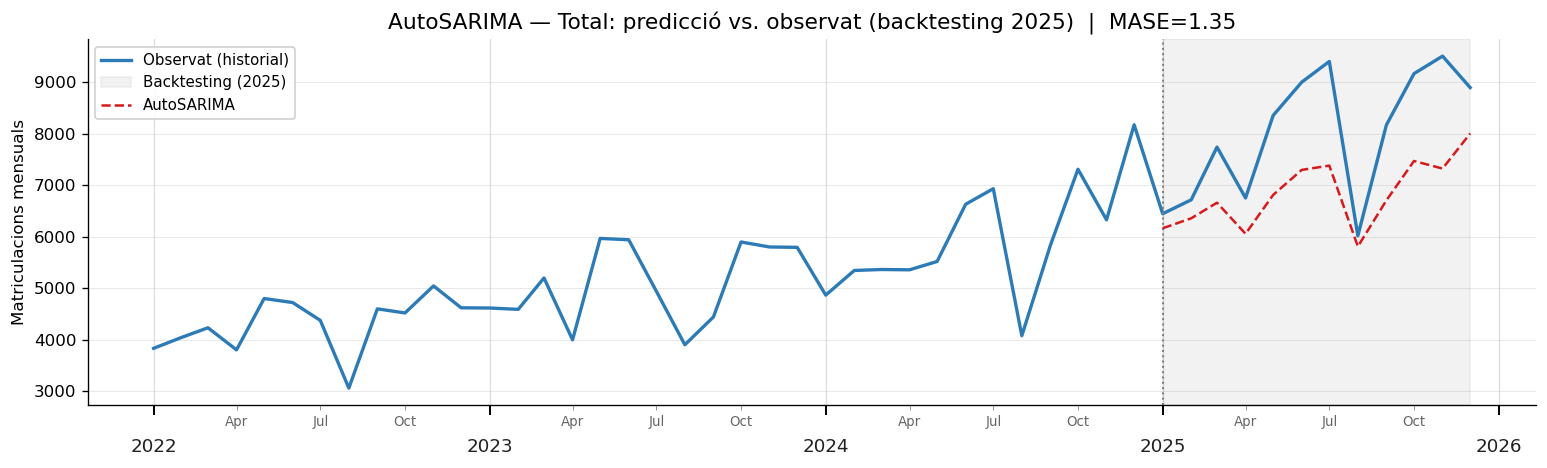

In [6]:
tech = 'Total'
fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot = pivot_train[tech].iloc[-36:]
y_test_plot  = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                   (df_forecasts['Model'] == 'AutoSARIMA')].sort_values('date')
ax.plot(sub['date'], sub['predicted'], color='#d7191c', lw=1.5, ls='--', label='AutoSARIMA')

mase_val = df_metrics[df_metrics['Tecnologia'] == tech]['MASE'].values[0]
ax.set_title(f'AutoSARIMA — {tech}: predicció vs. observat (backtesting 2025)  |  MASE={mase_val:.2f}', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_10_sarima_total.png', bbox_inches='tight')
plt.show()

## 5. Guardar resultats


In [7]:
df_forecasts.to_csv(RESULTS_DIR / 'sarima_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'sarima_metrics.csv', index=False)
orders_df.to_csv(RESULTS_DIR / 'sarima_orders.csv', index=False)
print('Guardats: sarima_forecasts.csv, sarima_metrics.csv, sarima_orders.csv')

Guardats: sarima_forecasts.csv, sarima_metrics.csv, sarima_orders.csv
